
## Precios de viviendas en California 1990
### Elavorado por:
Gerardo Villarraga y Santiago Sierra

## objetivo:
por medio de un conjunto de datos tomado del la paguina Kaglee de un senso a los precios de las viviendas en california en los años 1990, trabajar el conjunto de datos para crear un modelo capas de predecir el precio que tendria una vivienda (escribir mejor esta parte)


Empezamos llamando a todas las liberias que utulizaremos durante el proceso y definimor el Dataframe para aanlizar el comportamiento de los datos que tenemos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pycaret

# Cargar archiv
df = pd.read_csv('../data/housing.csv')

display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [2]:
df.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

In [3]:
#información general
display(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


None

Se le realizo un analisis estadistico basico a todos los datos del dataframe para el identificar el corportamiento de cada uno de ellos.

In [4]:
#esto tiwene media y desviacion estandar
print("Resumen estadístico")
display(df.describe())

Resumen estadístico


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Aqui, tras el analizar la naturaleza de nuestros datos revizaremos la estructura individual de los datos cruciales, iniciamos las variables respecto a la proximidad con el oceano pacifico con las viviendas, desde las viviendas con una cercania al mar hasta aquellas con limmitado acceso al mismo.

In [5]:
col = "ocean_proximity"

conteo = df[col].value_counts()
conteo.plot(kind='pie', autopct='%1.1f%%', startangle=90)

plt.title('Gráfico de pastel de '+ col)
plt.ylabel('')
plt.show()

<Figure size 640x480 with 1 Axes>

en este apartado se da un analisis estadistico respecto al valor medio de las casas, encontrando como los precios mas bajos y altos junto al valor promedio en venta.

In [6]:
columna = 'median_house_value'

print("Media:", df[columna].mean())
print("Mediana:", df[columna].median())
print("Moda:\n", df[columna].mode())

print("Mínimo:", df[columna].min())
print("Máximo:", df[columna].max())

print("Cuartiles:\n", df[columna].quantile([0.25, 0.5, 0.75]))
print("Desviación estándar:", df[columna].std())

Media: 206855.81690891474
Mediana: 179700.0
Moda:
 0    500001.0
Name: median_house_value, dtype: float64
Mínimo: 14999.0
Máximo: 500001.0
Cuartiles:
 0.25    119600.0
0.50    179700.0
0.75    264725.0
Name: median_house_value, dtype: float64
Desviación estándar: 115395.61587441387


Tras el analisis se sigue con el representar de forma grafica los precios mediante un grafico de barras

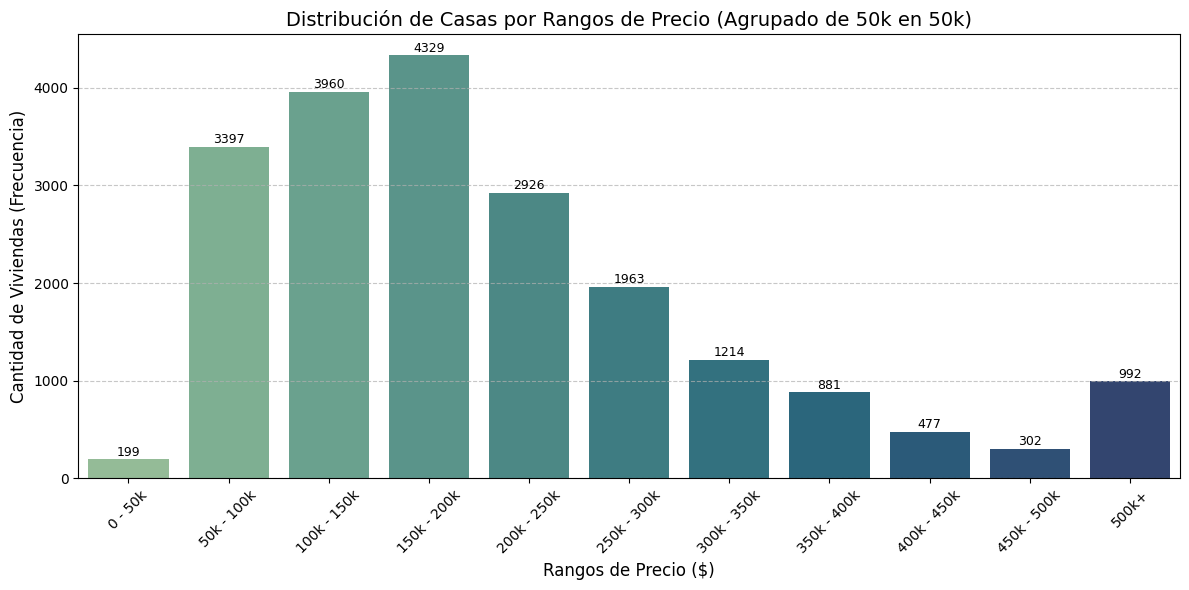

In [7]:
#Definir grupos (de 50,000 en 50,000 )
bins = [0, 50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, float('inf')]

etiquetas = [
    '0 - 50k', '50k - 100k', '100k - 150k', '150k - 200k', '200k - 250k',
    '250k - 300k', '300k - 350k', '350k - 400k', '400k - 450k', '450k - 500k', '500k+'
]

# 3. Crear una columna temporal con la categoría de precio correspondiente
df['rango_precio'] = pd.cut(df['median_house_value'], bins=bins, labels=etiquetas, right=False)

# 4. Generar el gráfico de barras con la frecuencia de cada grupo
plt.figure(figsize=(12, 6))
conteo_rangos = df['rango_precio'].value_counts().sort_index()

ax = sns.barplot(x=conteo_rangos.index, y=conteo_rangos.values, palette='crest', hue=conteo_rangos.index, legend=False)

plt.title('Distribución de Casas por Rangos de Precio (Agrupado de 50k en 50k)', fontsize=14)
plt.xlabel('Rangos de Precio ($)', fontsize=12)
plt.ylabel('Cantidad de Viviendas (Frecuencia)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Añadir los números exactos encima de cada barra para mayor claridad visual
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 5),
                textcoords='offset points',
                fontsize=9)

plt.tight_layout()
plt.show()

Aqui se desarrollo el sesgo estaditico de las variables para el detectar si tienen una distribuicon normal o sesgada en alguna dirrecion
y se graficaron las mas importantes para ver su comportamiento.

In [8]:
# Ver el sesgo estadístico de las variables numéricas
skewness = df.select_dtypes(include=['float64', 'int64']).skew()
print("--- Nivel de Sesgo (Skewness) ---")
print(skewness)

--- Nivel de Sesgo (Skewness) ---
longitude            -0.297801
latitude              0.465953
housing_median_age    0.060331
total_rooms           4.147343
total_bedrooms        3.459546
population            4.935858
households            3.410438
median_income         1.646657
median_house_value    0.977763
dtype: float64


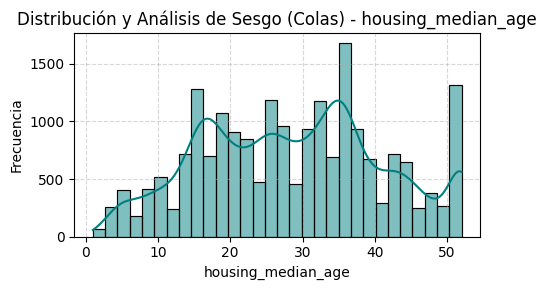

In [9]:
columna_a_analizar = 'housing_median_age'

# (Histograma + Curva de Densidad)
plt.figure(figsize=(5, 3))
sns.histplot(df[columna_a_analizar], kde=True, color='teal', bins=30)

plt.title(f'Distribución y Análisis de Sesgo (Colas) - {columna_a_analizar}')
plt.xlabel(columna_a_analizar)
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


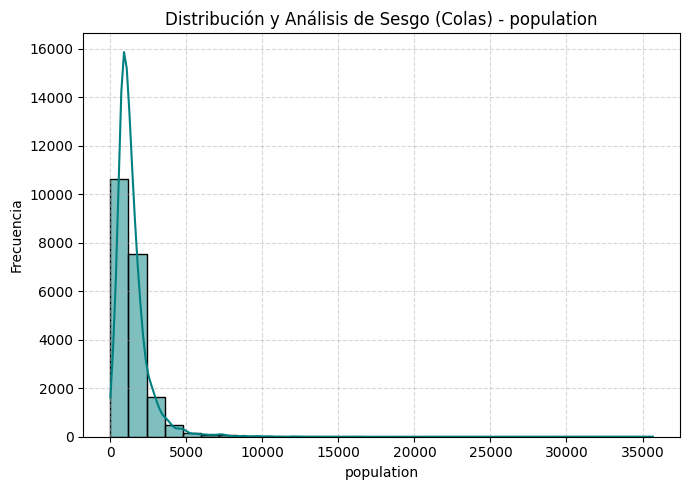

In [10]:
columna_a_analizar = 'population'

# (Histograma + Curva de Densidad)
plt.figure(figsize=(7, 5))
sns.histplot(df[columna_a_analizar], kde=True, color='teal', bins=30)

plt.title(f'Distribución y Análisis de Sesgo (Colas) - {columna_a_analizar}')
plt.xlabel(columna_a_analizar)
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


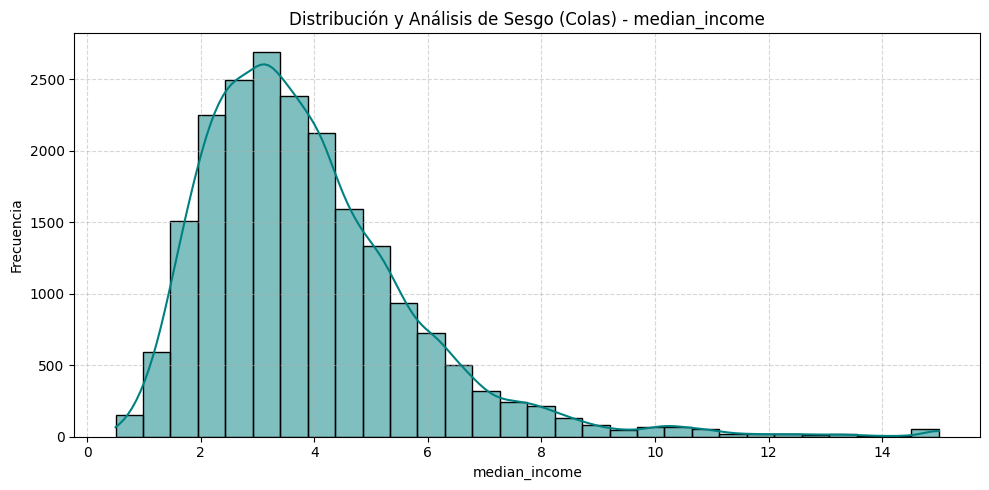

In [11]:
columna_a_analizar = 'median_income'

# (Histograma + Curva de Densidad)
plt.figure(figsize=(10, 5))
sns.histplot(df[columna_a_analizar], kde=True, color='teal', bins=30)

plt.title(f'Distribución y Análisis de Sesgo (Colas) - {columna_a_analizar}')
plt.xlabel(columna_a_analizar)
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

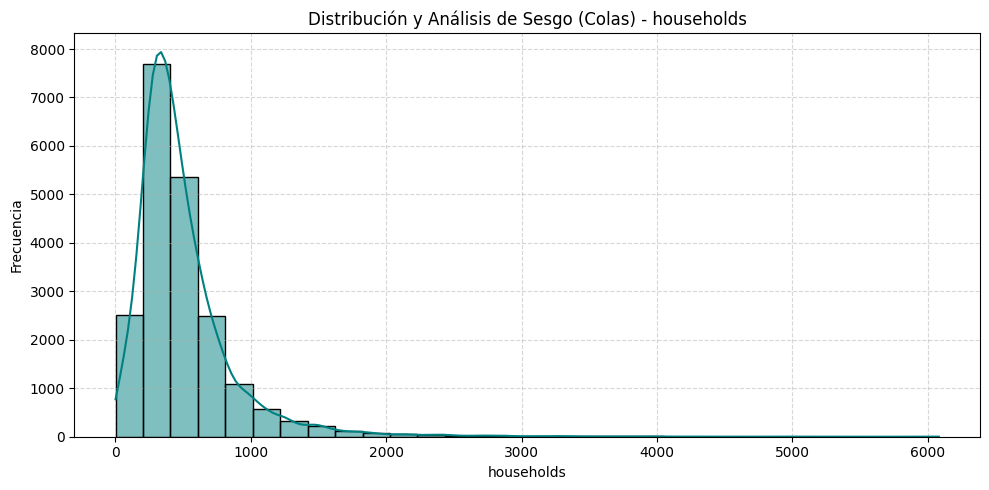

In [12]:
columna_a_analizar = 'households'

# (Histograma + Curva de Densidad)
plt.figure(figsize=(10, 5))
sns.histplot(df[columna_a_analizar], kde=True, color='teal', bins=30)

plt.title(f'Distribución y Análisis de Sesgo (Colas) - {columna_a_analizar}')
plt.xlabel(columna_a_analizar)
plt.ylabel('Frecuencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Ahora se hace la matriz de correlacion donde se comparan que relacion tienen las diferentes variantes entre si.

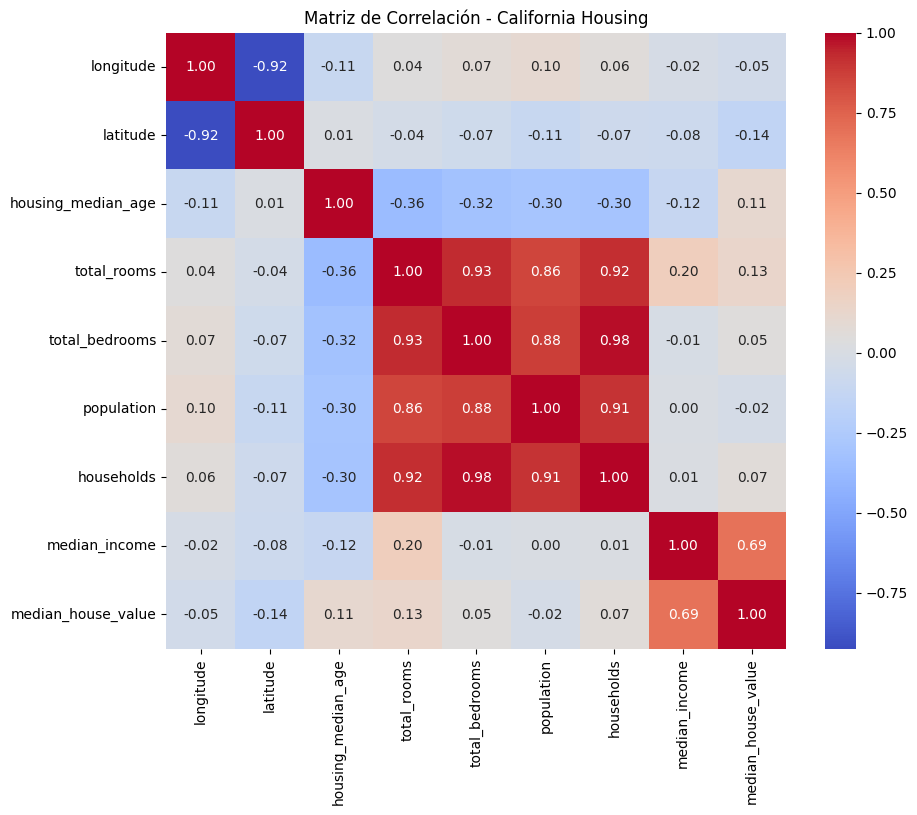

In [13]:
# Matriz de correlación
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include=['float64', 'int64']).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Matriz de Correlación - California Housing")
plt.show()

con los datos de longitud y latitud graficamos un mapa sobre la distribucion de las viviendas en el territorio de california, mostrando la varianza del precio y la cantidad de viviendas por condados.

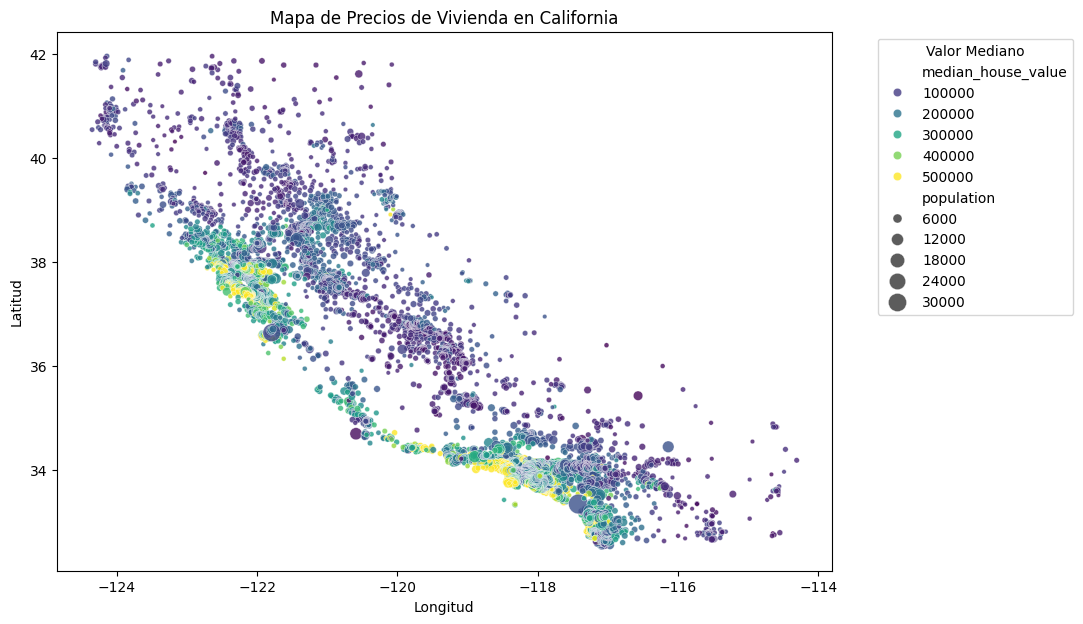

In [14]:
# dispersión geográfico coloreado
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='longitude', y='latitude',
    data=df,
    hue='median_house_value',
    palette='viridis',
    alpha=0.8,
    size='population',
    sizes=(10, 200)
)
plt.title("Mapa de Precios de Vivienda en California")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.legend(title="Valor Mediano", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## Conclucion:

Con el analisis inicial de la data que vamos a manejar podemos identificar una alta relacion entre las variables de total_rooms, total_bedrooms, population y households, lo que puede permitirnos despues crear nuevas variables a partir de estas q tengan mas peso en el modelo y que este no aprenda de datos casi duplicados, ademas podemos ver que el la distribucion de los precios tambien tienen un relacion con su hubicacion lo que moestra que esta informacion tambien puede ser valiosa para el modelo